# Reconnaissance de billets de banque par ORB + RANSAC
**Cours de Reconnaissance des formes – Master 1 IA & Sciences des données (UNIKIN)**
**Sujet 39, variante A** : reconnaissance de billets de banque (francs congolais) par descripteurs ORB,
appariement de Hamming et estimation robuste d'une homographie par RANSAC, par rapport à des images de référence.

Ce notebook sert à la démonstration de la soutenance. Il suit la chaîne de traitement pas à pas, puis
reprend les résultats chiffrés du protocole complet (`code/experiences.py`) et compare avec la variante B
(histogrammes de couleur HSV + texture LBP + k-NN). Aucune méthode d'apprentissage profond n'est utilisée.

**Sur Google Colab** : cloner le dépôt (`!git clone <url> reconnaissance_formes` dans `/content`) ou téléverser
l'archive du projet, puis exécuter les cellules dans l'ordre. Les images de billets sont téléchargées automatiquement.

In [1]:
import os, sys, glob, json, zipfile
from pathlib import Path

# Sur Colab : décompresser l'archive du projet si elle a été téléversée
if Path('/content').exists() and not Path('/content/reconnaissance_formes').exists():
    archives = glob.glob('/content/*.zip')
    if archives:
        zipfile.ZipFile(archives[0]).extractall('/content')
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'opencv-python-headless', 'scikit-image'])
if Path('/content/reconnaissance_formes').exists():
    RACINE = Path('/content/reconnaissance_formes')
else:  # exécution locale : le notebook est à la racine du projet
    RACINE = Path('.').resolve() if (Path('.') / 'code').exists() else Path('..').resolve()
sys.path.insert(0, str(RACINE / 'code'))
os.chdir(RACINE / 'code')

# Images de billets absentes (dépôt public) : téléchargement depuis la source d'origine
if not any((RACINE / 'donnees' / 'billets_publics').glob('*.jpg')):
    import subprocess
    subprocess.run([sys.executable, 'telecharger_billets.py', '--sortie', str(RACINE / 'donnees' / 'billets_publics')], check=True)

import cv2, numpy as np, matplotlib.pyplot as plt, pandas as pd
from billets import ReconnaisseurORB, ReconnaisseurHistogrammes, charger_image, INCONNU
from billets.pretraitement import preparer_gris, redimensionner
from billets.synthese import generer_photo, CATEGORIES
from billets.evaluation import iou_quadrilateres
from config_billets import CONNUS, NEG_TEST
from demo import annoter, dessiner_appariements
print('OpenCV', cv2.__version__, '| racine du projet :', RACINE)
REFS = RACINE / 'donnees' / 'billets_publics'
rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

téléchargé 100k_Zaire.jpg
téléchargé 100_Billion_Zimbabwe.jpg


téléchargé 1000_Rouble.jpg
téléchargé 500_Angola.jpg


téléchargé 10k_Liban.jpg
téléchargé 1_million_bolivar.jpg


téléchargé 200k_nicaragua.jpg
téléchargé 10k_Zlotych.jpg


téléchargé 1000_Cruzados.jpg
téléchargé 1_million_Intis.jpg


...

téléchargé F2-7 20k_cheque_ZWD.jpg
téléchargé F2-8 50_cents_ZWN.jpg


téléchargé F2-9 5_Billions_ZWN.jpg


téléchargé TizMillio_B_Pengo.jpg
téléchargé _million_mark.jpg


téléchargé million_mark.jpg
44 images dans reconnaissance-billets-orb-ransac/donnees/billets_publics


OpenCV 5.0.0 | racine du projet : reconnaissance-billets-orb-ransac


## 1. Les images de référence
Le système ne dispose que d'**une seule image de référence par billet** (une par face pour les vrais billets).
En attendant des photos de billets congolais, la chaîne est validée sur 12 billets publics
(collection de l'*Hyperinflation Archive*), avec exactement le même protocole.

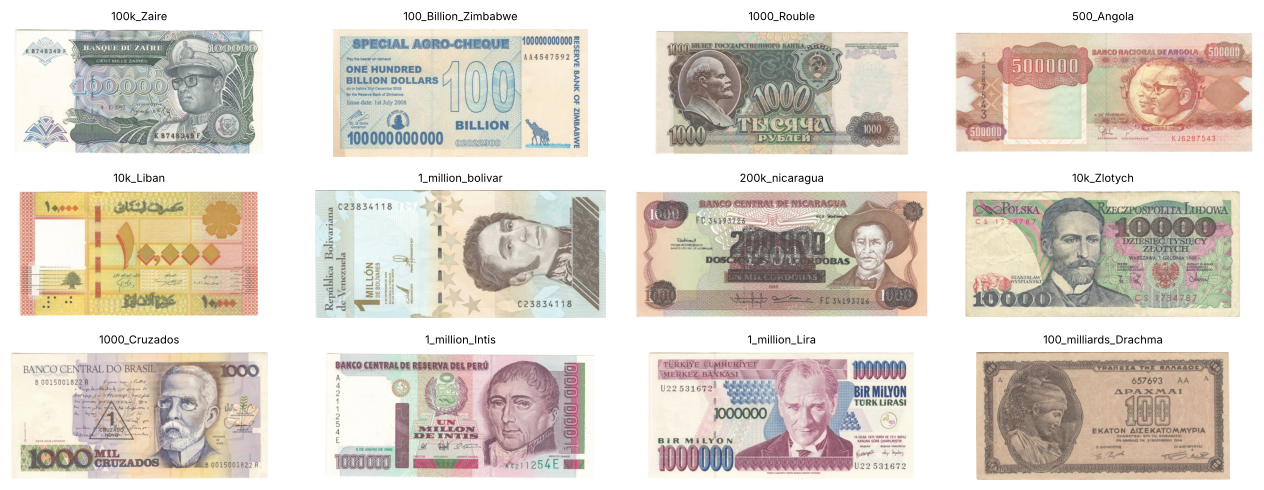

In [2]:
fig, axes = plt.subplots(3, 4, figsize=(13, 5))
for ax, c in zip(axes.ravel(), CONNUS):
    ax.imshow(rgb(charger_image(REFS / f'{c}.jpg'))); ax.set_title(c, fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Étape 1 – Points d'intérêt ORB
ORB = détecteur **FAST** orienté (orientation par centroïde d'intensité) + descripteur **BRIEF** binaire de
256 bits « tourné » selon cette orientation, calculé sur une pyramide de 8 échelles (facteur 1,2).
Prétraitement : niveaux de gris + égalisation locale CLAHE.

100k_Zaire                2000 points ORB
100_Billion_Zimbabwe      2000 points ORB
1000_Rouble               2000 points ORB
500_Angola                2000 points ORB
10k_Liban                 2000 points ORB
1_million_bolivar         2000 points ORB
200k_nicaragua            2000 points ORB
10k_Zlotych               2000 points ORB


1000_Cruzados             2000 points ORB
1_million_Intis           2000 points ORB
1_million_Lira            2000 points ORB
100_milliards_Drachma     2000 points ORB


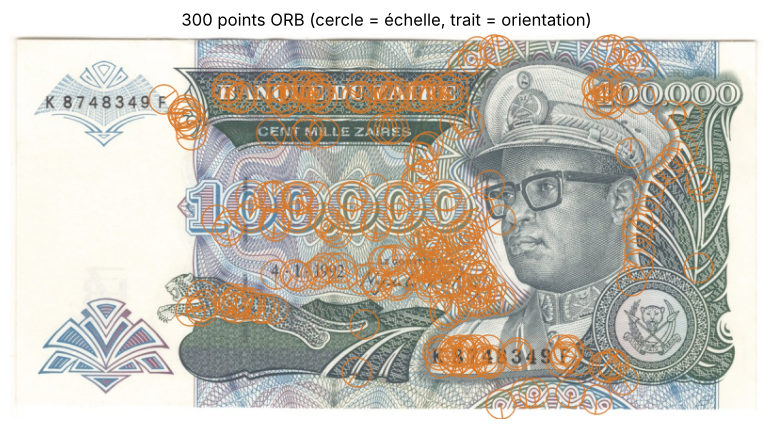

Un descripteur ORB = 32 octets = 256 bits


In [3]:
reco = ReconnaisseurORB(n_points=2000, ratio=0.75, seuil_ransac=5.0, tau=7, relance_zoom=True)  # configuration retenue
for c in CONNUS:
    n = reco.ajouter_reference(c, charger_image(REFS / f'{c}.jpg'))
    print(f'{c:24s} {n:5d} points ORB')
ref = reco.references[0]
vis = cv2.drawKeypoints(ref['image'], ref['kp'][:300], None, color=(42,120,214),
                        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(10,5)); plt.imshow(rgb(vis)); plt.axis('off'); plt.title('300 points ORB (cercle = échelle, trait = orientation)'); plt.show()
print('Un descripteur ORB =', ref['des'].shape[1], 'octets =', ref['des'].shape[1]*8, 'bits')

## 3. Étapes 2 à 4 – Appariement de Hamming, test de ratio de Lowe, RANSAC
On fabrique une photo difficile (perspective forte, fond encombré) dont on connaît la vérité terrain,
puis on suit chaque étape.

In [4]:
rng = np.random.default_rng(7)
billet = charger_image(REFS / '100k_Zaire.jpg')
photo, quad_vrai = generer_photo(rng, billet, 'perspective', distracteur=charger_image(REFS / '500k_Zaire.jpg'))

kp, des, f, forme = reco.extraire(photo)
ref = next(r for r in reco.references if r['classe'] == '100k_Zaire')
paires = reco.apparieur.knnMatch(ref['des'], des, k=2)
bons = [m for m, *n in paires if n and m.distance < 0.75 * n[0].distance]
src = np.float32([ref['kp'][m.queryIdx].pt for m in bons]).reshape(-1,1,2)
dst = np.float32([kp[m.trainIdx].pt for m in bons]).reshape(-1,1,2)
H, masque = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
print(f'points ORB dans la photo        : {len(kp)}')
print(f'appariements bruts (k=2)         : {len(paires)}')
print(f'après test de ratio de Lowe 0.75 : {len(bons)}')
print(f'inliers RANSAC (homographie)     : {int(masque.sum())}')
print('Homographie estimée H =\n', np.round(H, 3))

points ORB dans la photo        : 2000
appariements bruts (k=2)         : 2000
après test de ratio de Lowe 0.75 : 146
inliers RANSAC (homographie)     : 137
Homographie estimée H =
 [[-4.23000e-01 -1.57000e-01  7.26611e+02]
 [-8.30000e-02 -6.74000e-01  6.49279e+02]
 [ 0.00000e+00 -0.00000e+00  1.00000e+00]]


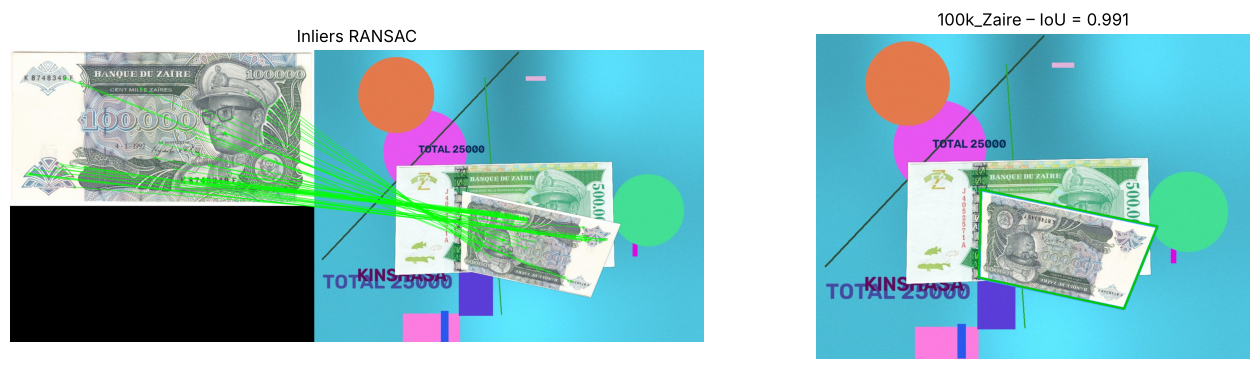

Scores (inliers) par billet de référence : {'100k_Zaire': 137, '200k_nicaragua': 4, '100_Billion_Zimbabwe': 0, '1000_Rouble': 0, '500_Angola': 0, '10k_Liban': 0, '1_million_bolivar': 0, '10k_Zlotych': 0, '1000_Cruzados': 0, '1_million_Intis': 0, '1_million_Lira': 0, '100_milliards_Drachma': 0}


In [5]:
res = reco.predire(photo, details=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios':[1.6,1]})
axes[0].imshow(rgb(dessiner_appariements(photo, res, 60))); axes[0].axis('off'); axes[0].set_title('Inliers RANSAC')
vis = photo.copy()
cv2.polylines(vis, [quad_vrai.astype(np.int32)], True, (255,160,60), 6)
cv2.polylines(vis, [res['polygone'].astype(np.int32)], True, (0,200,0), 3)
axes[1].imshow(rgb(vis)); axes[1].axis('off')
axes[1].set_title(f"{res['classe']} – IoU = {iou_quadrilateres(res['polygone'], quad_vrai):.3f}")
plt.show()
print('Scores (inliers) par billet de référence :', dict(sorted(res['scores'].items(), key=lambda x: -x[1])))

## 4. Étape 5 – Décision en monde ouvert (rejet des billets inconnus)
La coupure retenue est celle qui a le plus d'inliers ; si ce nombre est inférieur au seuil **τ**
(choisi sur le jeu de validation), la photo est rejetée. Exemple : un billet qui n'est pas dans la base
(500 000 zaïres, « cousin » du 100 000 zaïres connu) et une scène sans billet.

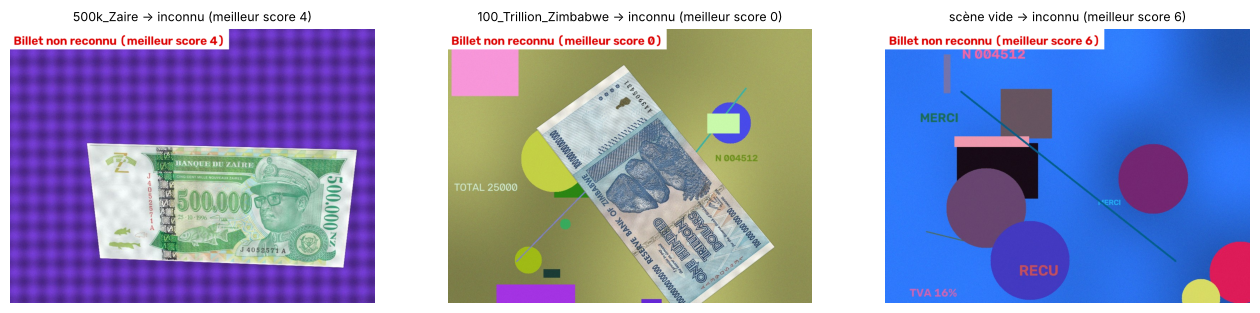

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
cas = [('500k_Zaire', 'facile'), ('100_Trillion_Zimbabwe', 'rotation'), (None, 'facile')]
for ax, (nom, cat) in zip(axes, cas):
    img, _ = generer_photo(rng, charger_image(REFS / f'{nom}.jpg') if nom else None, cat)
    r = reco.predire(img)
    ax.imshow(rgb(annoter(img, r))); ax.axis('off')
    ax.set_title(f"{nom or 'scène vide'} -> {r['classe']} (meilleur score {r['score']})", fontsize=9)
plt.show()

## 5. Démonstration sur toutes les difficultés
Une photo par catégorie : rotation, perspective, petite échelle, éclairage, flou, occlusion par la main,
billet froissé, forte compression.

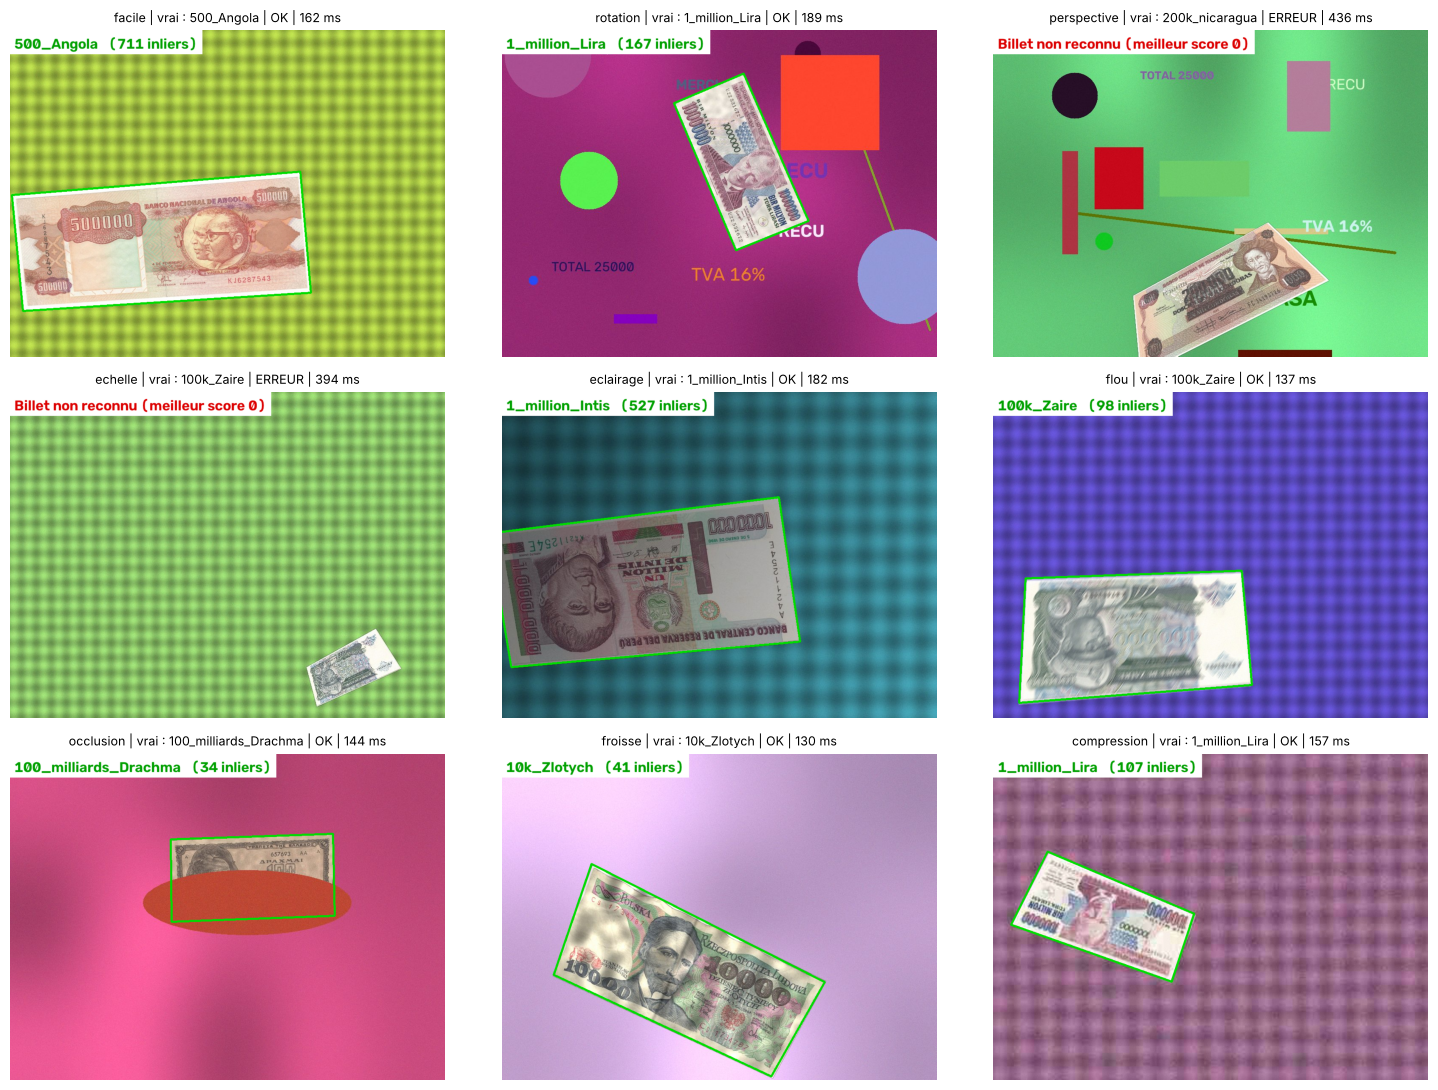

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, cat in zip(axes.ravel(), CATEGORIES):
    c = CONNUS[rng.integers(len(CONNUS))]
    img, quad = generer_photo(rng, charger_image(REFS / f'{c}.jpg'), cat)
    r = reco.predire(img)
    ok = 'OK' if r['classe'] == c else 'ERREUR'
    ax.imshow(rgb(annoter(img, r))); ax.axis('off')
    ax.set_title(f"{cat} | vrai : {c} | {ok} | {r['temps_ms']:.0f} ms", fontsize=9)
plt.tight_layout(); plt.show()

**Lecture des erreurs.** Les photos tirées au hasard ici contiennent deux échecs typiques : un billet coupé par le
bord de l'image et fortement incliné (une partie des points de la référence n'existe pas dans la photo), et un billet
minuscule posé sur un fond très texturé. Dans ce dernier cas, le fond quadrillé produit beaucoup de coins FAST et
absorbe une grande partie du budget de 2 000 points ORB, même après l'agrandissement x2 : il reste trop peu de points
sur le billet pour atteindre le seuil. C'est une limite réelle de la méthode, discutée dans le rapport.

## 6. Résultats du protocole complet
`code/construire_jeux.py` génère 336 photos de validation, 680 photos de test et 858 photos d'apprentissage
pour la variante B ; `code/experiences.py` règle les hyperparamètres sur la validation puis mesure une seule
fois sur le test (dont 22 billets inconnus jamais vus et 50 scènes sans billet). On recharge ici ses résultats.

In [8]:
RES = RACINE / 'resultats'
syn = json.load(open(RES / 'synthese.json', encoding='utf-8'))
cles = ['exactitude','precision_macro','rappel_macro','f1_macro','taux_identification','taux_confusion',
        'taux_faux_rejet','taux_fausse_acceptation','temps_ms_moyen']
tab = pd.DataFrame({'A : ORB + RANSAC': {k: syn['A']['test'][k] for k in cles},
                    'B : HSV + LBP + k-NN': {k: syn['B']['test'][k] for k in cles}}).round(3)
print('Configuration A :', syn['A']['configuration'], '| tau =', syn['A']['tau'])
print('Configuration B :', syn['B']['descripteurs'], '| k =', syn['B']['k'], '| delta =', round(syn['B']['delta'], 3))
print('Localisation A : IoU moyen =', round(syn['A']['test']['iou_moyen'], 3),
      '| part IoU > 0,5 =', round(syn['A']['test']['part_iou_sup_0_5'], 3))
tab

Configuration A : référence | tau = 7
Configuration B : couleur seule | k = 7 | delta = 1.221
Localisation A : IoU moyen = 0.973 | part IoU > 0,5 = 0.988


,A : ORB + RANSAC,B : HSV + LBP + k-NN
exactitude,0.956,0.238
precision_macro,0.965,0.126
rappel_macro,0.972,0.120
f1_macro,0.966,0.121
taux_identification,0.972,0.120
taux_confusion,0.002,0.535
taux_faux_rejet,0.025,0.345
taux_fausse_acceptation,0.073,0.556
temps_ms_moyen,689.511,42.697


In [9]:
pd.read_csv(RES / 'test_par_categorie.csv').round(3)

,categorie,A_identification,B_identification,A_fausse_acceptation,B_fausse_acceptation
0,facile,1.000,0.250,0.097,0.484
1,rotation,1.000,0.125,0.091,0.773
2,perspective,0.875,0.188,0.136,0.591
3,echelle,0.938,0.062,0.045,0.636
4,eclairage,1.000,0.000,0.065,0.355
5,flou,0.938,0.104,0.029,0.629
6,occlusion,1.000,0.146,0.091,0.545
7,froisse,1.000,0.146,0.091,0.455
8,compression,1.000,0.062,0.049,0.585


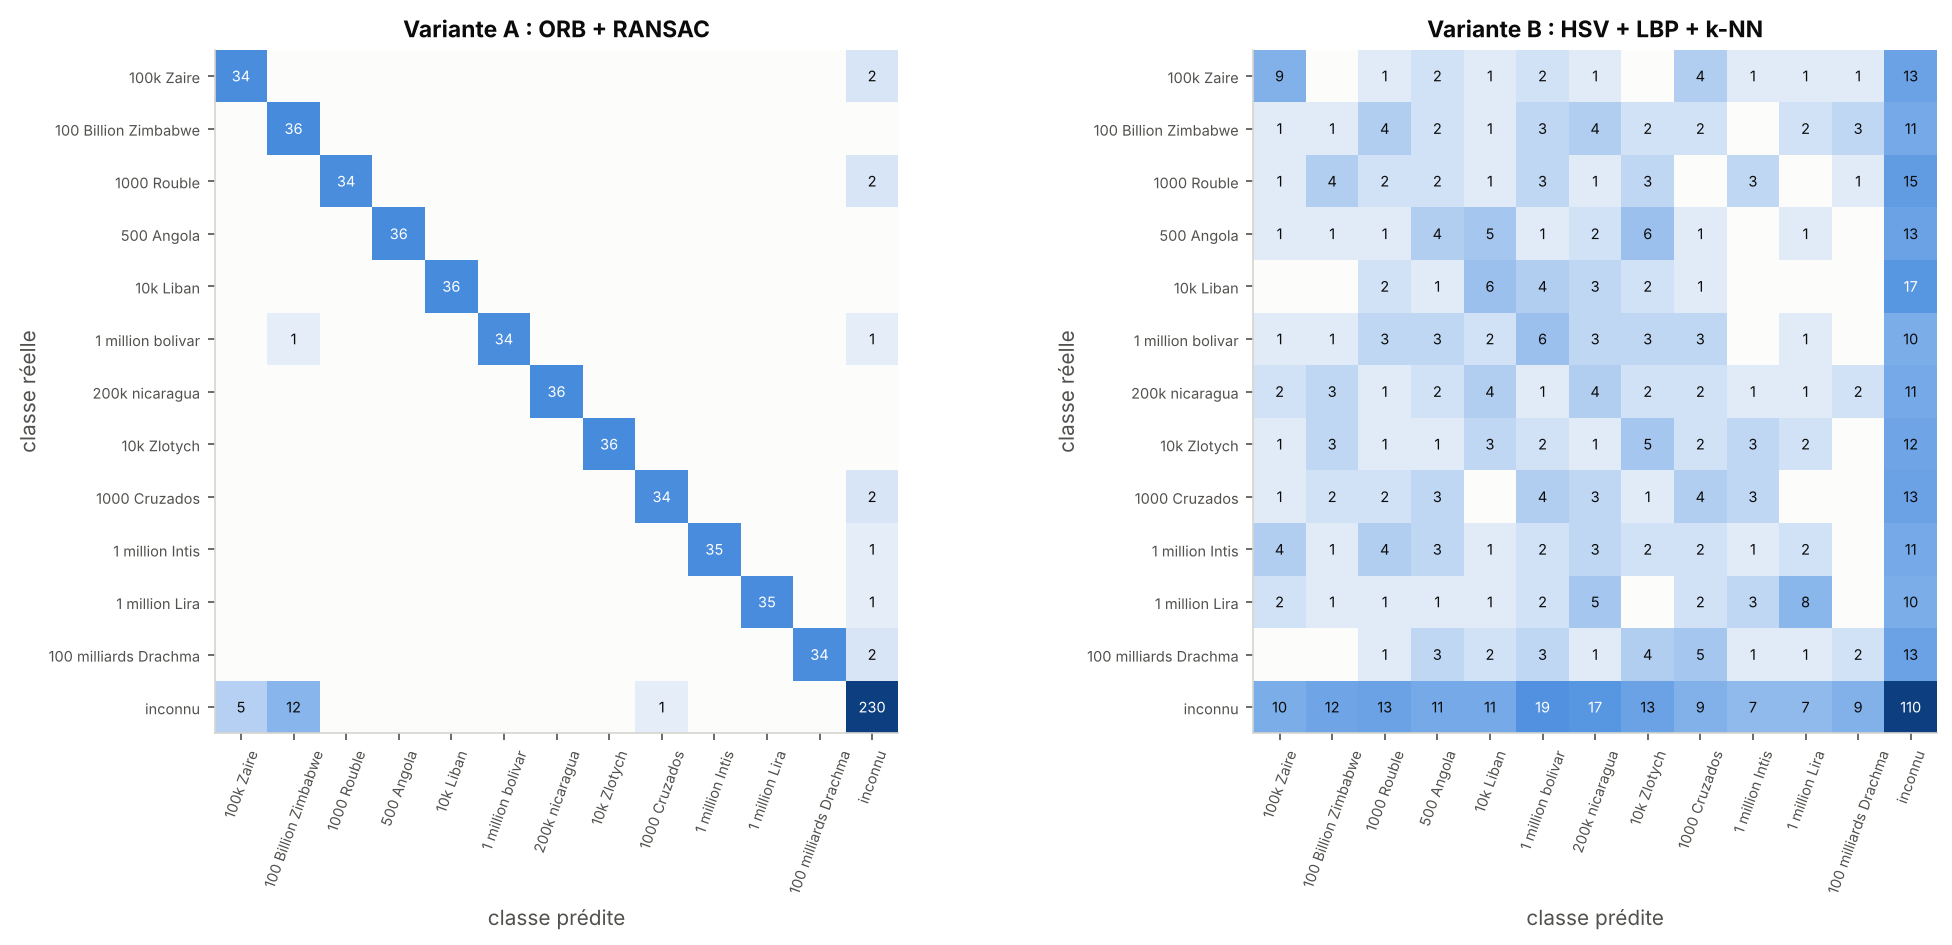

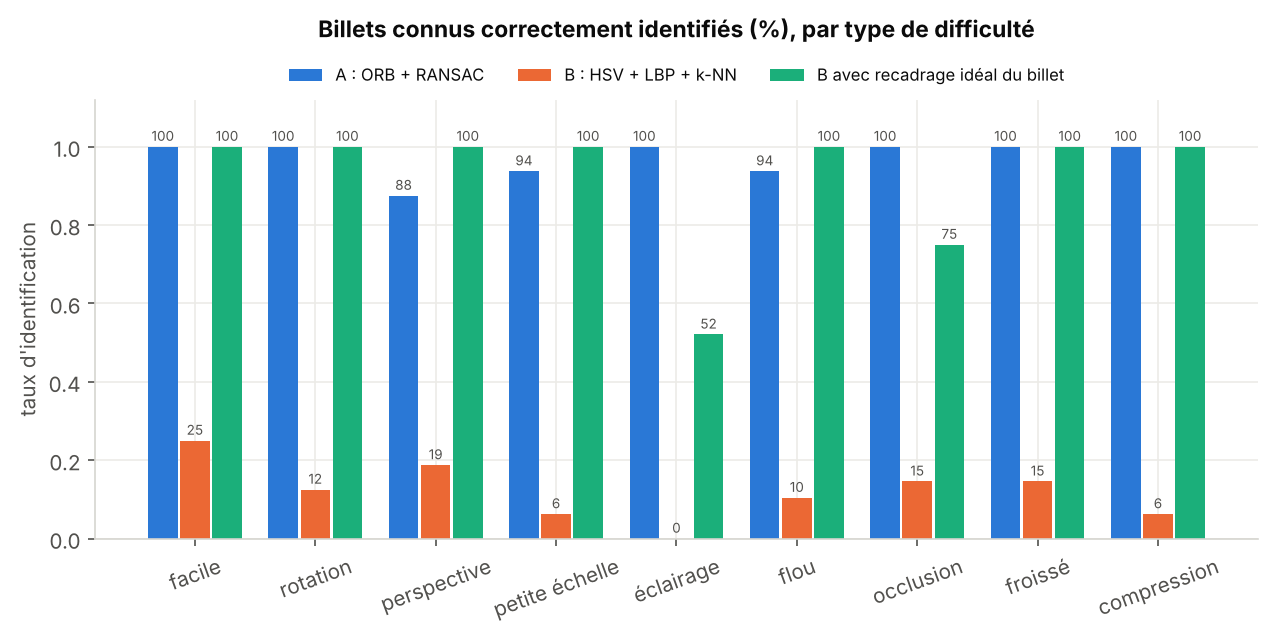

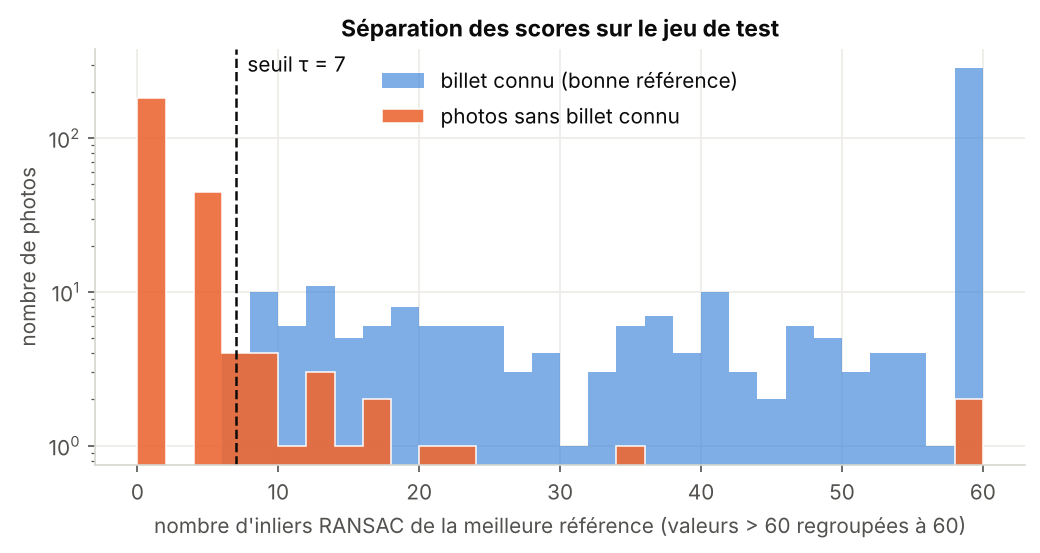

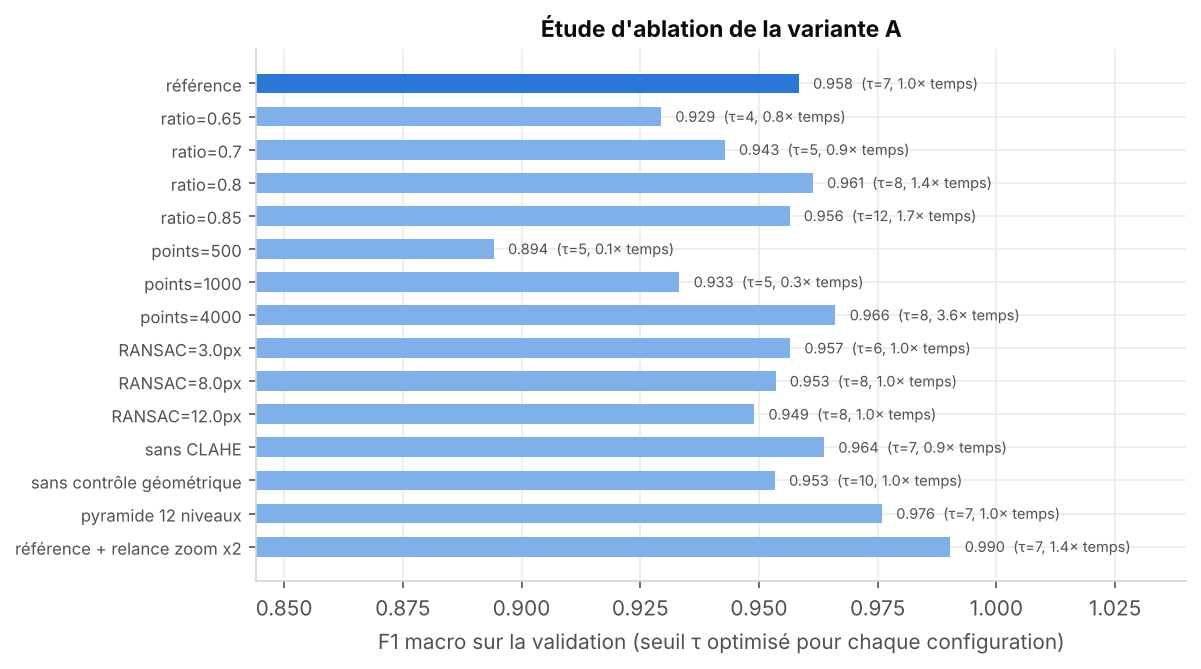

In [10]:
from IPython.display import Image, display
for f in ['09_matrices_confusion.png', '10_robustesse_categories.png', '07_distribution_scores.png', '11_ablation_a.png']:
    display(Image(filename=str(RACINE / 'figures' / f)))

## 7. Vérification rapide reproductible (sous-échantillon du test)
On ré-exécute ici la reconnaissance sur 90 photos du jeu de test (10 par catégorie) pour vérifier que l'on
retrouve les mêmes ordres de grandeur que le protocole complet.

In [11]:
import csv
dossier = RACINE / 'donnees' / 'synthetique' / 'test'
if (dossier / 'manifeste.csv').exists():
    lignes = list(csv.DictReader(open(dossier / 'manifeste.csv', encoding='utf-8')))
    reco_final = ReconnaisseurORB(**syn['A']['parametres'])
    for c in CONNUS:
        reco_final.ajouter_reference(c, charger_image(REFS / f'{c}.jpg'))
    ok, n = 0, 0
    for l in lignes:
        if not (dossier / l['fichier']).exists():
            continue
        r = reco_final.predire(charger_image(dossier / l['fichier']))
        ok += r['classe'] == l['classe']; n += 1
    print(f'{ok}/{n} photos correctement traitées ({ok/max(n,1):.1%})')
else:
    print("Jeu de test absent : lancer `python construire_jeux.py` (environ 5 minutes)")

Jeu de test absent : lancer `python construire_jeux.py` (environ 5 minutes)


## 8. Variante B en bref (pour la comparaison)
Descripteur global : histogramme HSV (teinte × saturation, valeur) + histogrammes LBP uniformes, comparés
par distance de Hellinger, décision par k-NN. Elle ne localise pas le billet et dépend du fond de l'image.

In [12]:
from billets.methode_hist import descripteur_histogrammes
img_a = charger_image(REFS / '100k_Zaire.jpg')
img_b, _ = generer_photo(rng, img_a, 'echelle')
img_c, _ = generer_photo(rng, img_a, 'facile')
da, db, dc = (descripteur_histogrammes(x) for x in (img_a, img_b, img_c))
print('distance référence <-> même billet, grand dans la photo :', round(float(np.linalg.norm(da - dc)), 3))
print('distance référence <-> même billet, petit dans la photo :', round(float(np.linalg.norm(da - db)), 3))
print('(la variante B voit surtout le fond quand le billet est petit ; ORB ne compare que les points appariés)')

distance référence <-> même billet, grand dans la photo : 1.273
distance référence <-> même billet, petit dans la photo : 1.396
(la variante B voit surtout le fond quand le billet est petit ; ORB ne compare que les points appariés)


## 9. Essayer sur sa propre photo
Sur Colab, téléverser une photo de billet puis exécuter la cellule suivante. Pour des billets congolais,
placer d'abord les images de référence (une par face) dans `donnees/references/`.

In [13]:
dossier_refs = RACINE / 'donnees' / 'references'
photos = sorted(glob.glob('/content/*.jpg')) if Path('/content').exists() else []
if photos:
    r2 = ReconnaisseurORB(tau=syn['A']['tau'], relance_zoom=True)
    for p in sorted(dossier_refs.glob('*.jpg')) if any(dossier_refs.glob('*.jpg')) else [REFS / f'{c}.jpg' for c in CONNUS]:
        classe, _, face = p.stem.rpartition('_') if p.stem.endswith(('_recto','_verso')) else (p.stem, '', '')
        r2.ajouter_reference(classe, charger_image(p), face)
    for p in photos:
        img = charger_image(p); r = r2.predire(img)
        plt.figure(figsize=(8,5)); plt.imshow(rgb(annoter(img, r))); plt.axis('off'); plt.show()
else:
    print('Aucune photo téléversée dans /content.')

Aucune photo téléversée dans /content.
